# 08 – Final Visualisation and Reporting

## Introduction

This notebook presents the overall findings of the machine learning project developed for menstrual cycle length prediction.

The previous notebooks covered dataset exploration, feature selection, data preprocessing, model training, model evaluation, cross-validation and Explainable AI using SHAP.

In this notebook, the results obtained from these stages are brought together through tables and visualisations.

The main objectives are:

1. Compare the performance of the four regression models.
2. Visualise the comparison between actual and predicted menstrual cycle lengths.
3. Evaluate machine learning models against the baseline model.
4. Visualise the importance of selected features using SHAP.
5. Summarise the overall findings and limitations of the project.

This notebook provides a consolidated overview of the machine learning workflow and its findings.

In [2]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
# Load cleaned dataset

df = pd.read_csv("../Dataset/menstrual_health_cleaned.csv")

print("Dataset shape:", df.shape)
print("Number of records:", len(df))

df.head()

Dataset shape: (81, 11)
Number of records: 81


,number_of_peak,Age,Length_of_cycle,Estimated_day_of_ovulution,Length_of_Leutal_Phase,Length_of_menses,Unusual_Bleeding,Weight,BMI,Mean_of_length_of_cycle,Menses_score
0,3,18,27,14,9,5,no,76.0,26.3,30,4.0
1,4,18,25,17,10,6,yes,76.0,26.3,30,5.0
2,2,19,30,17,13,4,no,56.0,21.9,30,2.0
3,3,19,28,16,14,6,no,61.0,25.4,30,3.0
4,2,19,35,18,15,5,no,55.0,21.5,35,5.0


In [4]:
# Separate independent and dependent variables

X = df.drop(columns=[
    "Length_of_cycle",
    "Mean_of_length_of_cycle",
    "Estimated_day_of_ovulution",
    "Weight"
])

y = df["Length_of_cycle"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (81, 7)
Target shape: (81,)


In [5]:
# Identify feature types

categorical_features = ["Unusual_Bleeding"]

numerical_features = [
    "number_of_peak",
    "Age",
    "Length_of_Leutal_Phase",
    "Length_of_menses",
    "BMI",
    "Menses_score"
]

# Define preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(
            drop="if_binary",
            handle_unknown="ignore"
        ), categorical_features)
    ]
)

# Define models

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        random_state=42
    ),

    "Support Vector Regression": SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    )
}

print("Preprocessing and models defined successfully!")

Preprocessing and models defined successfully!


In [6]:
# Define 5-fold cross-validation

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

# Evaluate models

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=kf,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        }
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_MAE"].mean(),
        "Mean RMSE": -scores["test_RMSE"].mean(),
        "Mean R2": scores["test_R2"].mean()
    })

cv_results = pd.DataFrame(cv_results)

print(cv_results.round(3))

                       Model  Mean MAE  Mean RMSE  Mean R2
0          Linear Regression     3.151      4.066   -0.006
1              Random Forest     3.532      4.368   -0.211
2          Gradient Boosting     3.535      4.466   -0.262
3  Support Vector Regression     2.987      4.090   -0.012


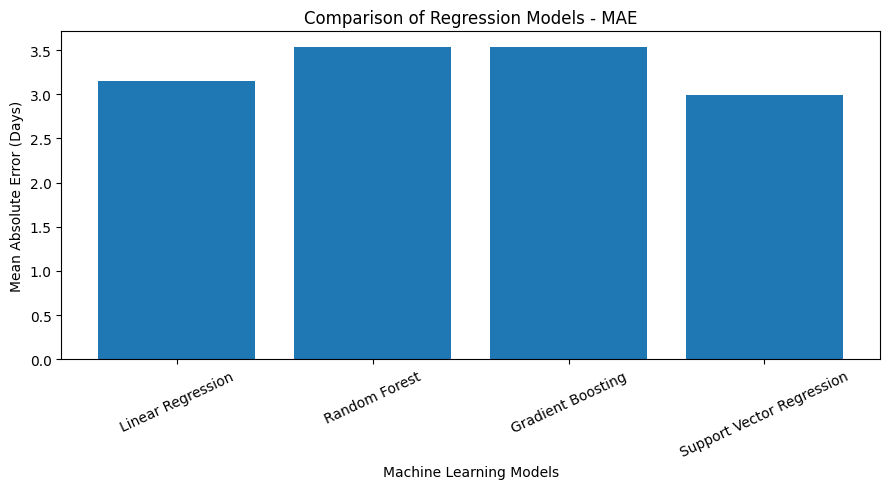

In [7]:
plt.figure(figsize=(9, 5))

plt.bar(
    cv_results["Model"],
    cv_results["Mean MAE"]
)

plt.title("Comparison of Regression Models - MAE")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error (Days)")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

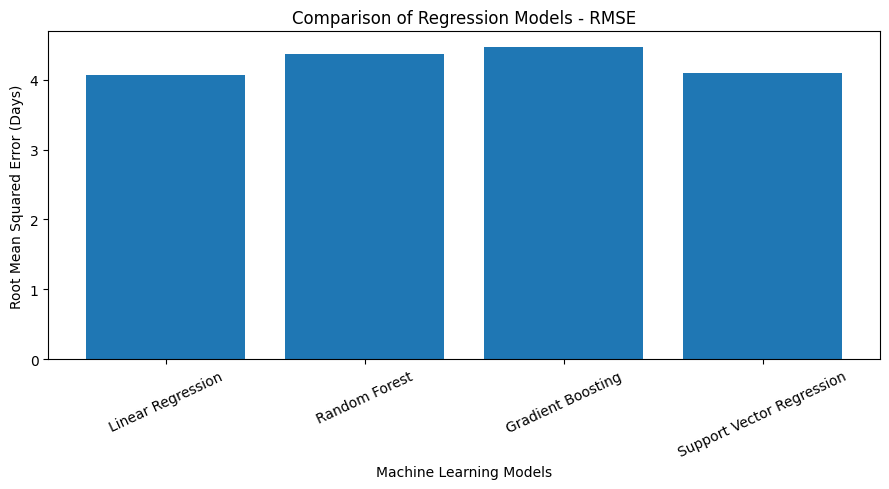

In [8]:
plt.figure(figsize=(9, 5))

plt.bar(
    cv_results["Model"],
    cv_results["Mean RMSE"]
)

plt.title("Comparison of Regression Models - RMSE")
plt.xlabel("Machine Learning Models")
plt.ylabel("Root Mean Squared Error (Days)")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

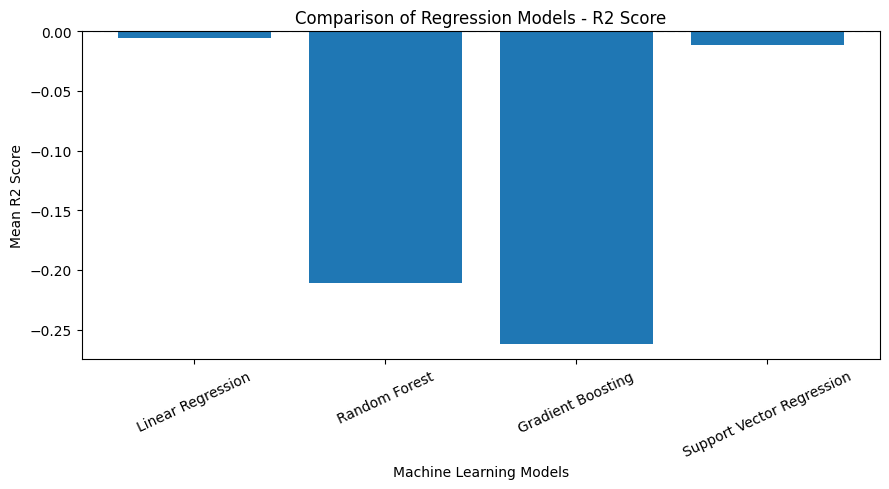

In [9]:
plt.figure(figsize=(9, 5))

plt.bar(
    cv_results["Model"],
    cv_results["Mean R2"]
)

plt.axhline(y=0, linestyle="--")

plt.title("Comparison of Regression Models - R2 Score")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean R2 Score")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [10]:
# Create baseline pipeline

baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="mean"))
])

# Perform cross-validation

baseline_scores = cross_validate(
    baseline_pipeline,
    X,
    y,
    cv=kf,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }
)

baseline_results = {
    "Model": "Baseline",
    "Mean MAE": -baseline_scores["test_MAE"].mean(),
    "Mean RMSE": -baseline_scores["test_RMSE"].mean(),
    "Mean R2": baseline_scores["test_R2"].mean()
}

print(pd.DataFrame([baseline_results]).round(3))

      Model  Mean MAE  Mean RMSE  Mean R2
0  Baseline     3.071      4.181   -0.052


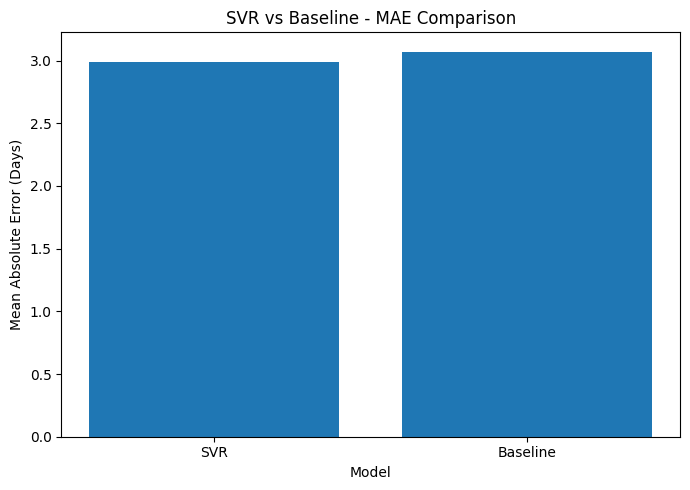

In [11]:
comparison_results = pd.DataFrame({
    "Model": ["SVR", "Baseline"],
    "MAE": [
        cv_results.loc[
            cv_results["Model"] == "Support Vector Regression",
            "Mean MAE"
        ].iloc[0],
        baseline_results["Mean MAE"]
    ]
})

plt.figure(figsize=(7, 5))

plt.bar(
    comparison_results["Model"],
    comparison_results["MAE"]
)

plt.title("SVR vs Baseline - MAE Comparison")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (Days)")

plt.tight_layout()
plt.show()

In [12]:
# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create SVR pipeline

svr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    ))
])

# Train model

svr_pipeline.fit(X_train, y_train)

# Generate predictions

y_pred = svr_pipeline.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [13]:
prediction_comparison = pd.DataFrame({
    "Actual Cycle Length": y_test.values,
    "Predicted Cycle Length": y_pred
})

prediction_comparison["Absolute Error"] = abs(
    prediction_comparison["Actual Cycle Length"] -
    prediction_comparison["Predicted Cycle Length"]
)

print(prediction_comparison.round(2))

    Actual Cycle Length  Predicted Cycle Length  Absolute Error
0                    30                   28.89            1.11
1                    27                   28.49            1.49
2                    35                   28.10            6.90
3                    25                   28.55            3.55
4                    28                   29.05            1.05
5                    29                   29.86            0.86
6                    30                   28.82            1.18
7                    30                   28.23            1.77
8                    35                   28.85            6.15
9                    37                   29.67            7.33
10                   28                   29.51            1.51
11                   30                   30.28            0.28
12                   30                   28.73            1.27
13                   27                   29.90            2.90
14                   28                 

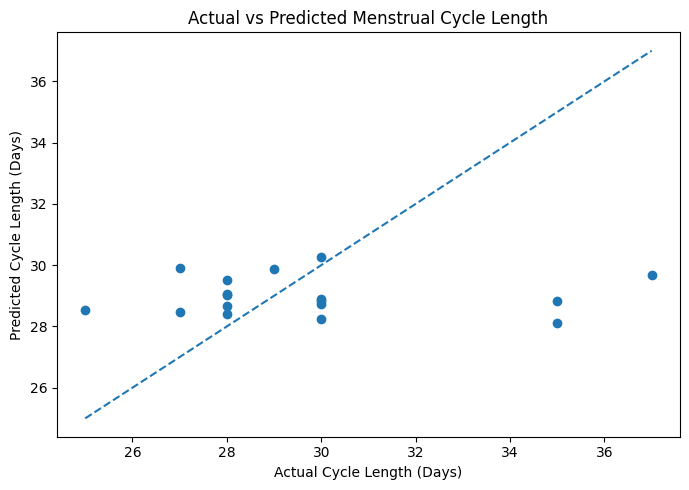

In [14]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Cycle Length (Days)")
plt.ylabel("Predicted Cycle Length (Days)")

plt.title("Actual vs Predicted Menstrual Cycle Length")

plt.tight_layout()
plt.show()

In [15]:
# Train SVR using the complete dataset

svr_full_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    ))
])

svr_full_pipeline.fit(X, y)

# Transform features

fitted_preprocessor = svr_full_pipeline.named_steps["preprocessor"]

X_processed = fitted_preprocessor.transform(X)

feature_names = fitted_preprocessor.get_feature_names_out()

X_processed_df = pd.DataFrame(
    X_processed,
    columns=feature_names
)

print("Processed dataset shape:", X_processed_df.shape)

Processed dataset shape: (81, 7)


In [16]:
# Create SHAP background dataset

background = shap.sample(
    X_processed_df,
    20,
    random_state=42
)

# Create explainer

explainer = shap.KernelExplainer(
    svr_full_pipeline.named_steps["model"].predict,
    background
)

# Calculate SHAP values

shap_values = explainer.shap_values(
    X_processed_df,
    nsamples=100
)

print("SHAP analysis completed!")

100%|██████████| 81/81 [00:05<00:00, 14.95it/s]

SHAP analysis completed!


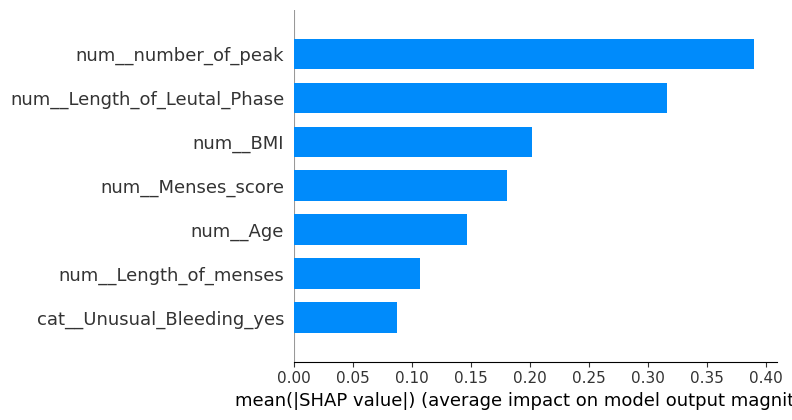

In [17]:
shap.summary_plot(
    shap_values,
    X_processed_df,
    plot_type="bar"
)

## Overall Interpretation

The machine learning models were compared using five-fold cross-validation to evaluate their performance in predicting menstrual cycle length.

Among the four regression models, Support Vector Regression achieved the lowest Mean MAE of approximately 2.987 days and Mean RMSE of approximately 4.090 days.

However, all four models produced negative mean R² scores, indicating limited predictive performance.

The baseline model achieved a Mean MAE of approximately 3.071 days. Although SVR showed a small improvement in MAE and RMSE, its predictive performance was not substantially better than the baseline.

The actual-versus-predicted visualisation demonstrated that the model did not consistently capture variations in cycle length.

SHAP analysis identified `number_of_peak` and `Length_of_Leutal_Phase` as the most influential features in the trained SVR model.

These findings represent patterns learned by the model and should not be interpreted as biological or clinical relationships.

## Project Limitations

1. **Small dataset:** The dataset contains only 81 unique records, which limits the ability of machine learning models to learn generalisable patterns.

2. **Limited predictive performance:** All four regression models produced negative mean R² scores during cross-validation.

3. **Limited feature availability:** The selected input features may not capture all factors associated with menstrual cycle variation.

4. **Model generalisation:** The performance observed on this dataset may not generalise to larger or different populations.

5. **Explainability limitations:** SHAP values describe the contributions of features to model predictions but do not establish biological causation.

6. **Clinical limitations:** The developed model is intended for educational and research purposes and is not suitable for medical diagnosis or clinical decision-making.

## Conclusion

This project explored the application of machine learning regression models and Explainable AI techniques for menstrual cycle length prediction.

Four regression algorithms were implemented and evaluated: Linear Regression, Random Forest, Gradient Boosting and Support Vector Regression.

Among these models, Support Vector Regression demonstrated the lowest prediction error during five-fold cross-validation. However, its improvement over the baseline model was small, and all models showed limited explanatory performance.

SHAP analysis provided insights into the contribution of individual features, identifying `number_of_peak` and `Length_of_Leutal_Phase` as the most influential features in the selected model.

Overall, this project provided practical experience in healthcare dataset preprocessing, regression modelling, model evaluation, cross-validation and Explainable AI.

Future improvements could include collecting a larger dataset, investigating additional relevant features, and evaluating model performance using independent external datasets.